# 01 · EDA del dataset municipal curated

Auditoría inicial del Parquet integrado: estructura, cobertura, periodos, distribuciones y valores extremos. Este notebook no modifica los datos de entrada.

In [8]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Mostraremos hasta 150 columnas y 150 filas
pd.set_option('display.max_columns', 150)
pd.set_option('display.max_rows', 150)

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_PATH = ROOT / 'data' / 'curated' / 'municipios.parquet'
REPORTS_DIR = ROOT / 'outputs' / 'reports'
FIGURES_DIR = ROOT / 'outputs' / 'figures'
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.is_file():
    raise FileNotFoundError(f'No existe el dataset curated: {DATA_PATH}')

# Leemos el dataset de municipios
df = pd.read_parquet(DATA_PATH)

# Mostramos el número de filas y columnas del dataset
print(f'Filas: {len(df)} | Columnas: {df.shape[1]}')
df.head()

Filas: 8132 | Columnas: 114


,codigo_ine,municipio,provincia,capital,poblacion_ign,superficie_km2,densidad_poblacion_hab_km2,longitud,latitud,codigo_comunidad,codigo_provincia,inmuebles_urbanos,valor_catastral_total_eur,valor_catastral_suelo_eur,superficie_urbana_m2,parcelas_urbanas,inmuebles_residenciales,valor_catastral_residencial_eur,valor_catastral_suelo_eur_m2,valor_catastral_residencial_medio_eur,inmuebles_urbanos_catastro_2021,valor_catastral_total_eur_catastro_2021,valor_catastral_suelo_eur_catastro_2021,superficie_urbana_m2_catastro_2021,parcelas_urbanas_catastro_2021,inmuebles_residenciales_catastro_2021,valor_catastral_residencial_eur_catastro_2021,valor_catastral_suelo_eur_m2_catastro_2021,valor_catastral_residencial_medio_eur_catastro_2021,edad_media_2025,porcentaje_poblacion_menor_18,porcentaje_poblacion_65_mas,diferencia_edad_media_1_anio,diferencia_edad_media_3_anios,saldo_total,saldo_interior,saldo_exterior,poblacion_2025,variacion_poblacion_1_anio,variacion_poblacion_3_anios,variacion_poblacion_5_anios,renta_neta_media_persona_eur,renta_neta_media_hogar_eur,tamanio_medio_hogar,viviendas_totales,viviendas_vacias,viviendas_uso_esporadico,porcentaje_viviendas_vacias,porcentaje_viviendas_uso_esporadico,viviendas_turisticas,plazas,plazas_por_vivienda,total_infracciones,distancia_costa_km,alquiler_precio_colectiva_mediana,alquiler_precio_colectiva_rango_intercuartilico,alquiler_precio_unifamiliar_mediana,alquiler_precio_unifamiliar_rango_intercuartilico,alquiler_superficie_colectiva_mediana,alquiler_superficie_colectiva_rango_intercuartilico,alquiler_superficie_unifamiliar_mediana,alquiler_superficie_unifamiliar_rango_intercuartilico,alquiler_colectiva_aproximado_eur_m2,alquiler_unifamiliar_aproximado_eur_m2,variacion_alquiler_precio_colectiva_mediana_1_anio,variacion_alquiler_precio_unifamiliar_mediana_1_anio,variacion_alquiler_colectiva_aproximado_eur_m2_1_anio,variacion_alquiler_unifamiliar_aproximado_eur_m2_1_anio,diferencia_alquiler_precio_colectiva_rango_intercuartilico_1_anio,diferencia_alquiler_precio_unifamiliar_rango_intercuartilico_1_anio,diferencia_alquiler_superficie_colectiva_mediana_1_anio,diferencia_alquiler_superficie_colectiva_rango_intercuartilico_1_anio,diferencia_alquiler_superficie_unifamiliar_mediana_1_anio,diferencia_alquiler_superficie_unifamiliar_rango_intercuartilico_1_anio,variacion_alquiler_precio_colectiva_mediana_3_anios,variacion_alquiler_precio_unifamiliar_mediana_3_anios,variacion_alquiler_colectiva_aproximado_eur_m2_3_anios,variacion_alquiler_unifamiliar_aproximado_eur_m2_3_anios,diferencia_alquiler_precio_colectiva_rango_intercuartilico_3_anios,diferencia_alquiler_precio_unifamiliar_rango_intercuartilico_3_anios,diferencia_alquiler_superficie_colectiva_mediana_3_anios,diferencia_alquiler_superficie_colectiva_rango_intercuartilico_3_anios,diferencia_alquiler_superficie_unifamiliar_mediana_3_anios,diferencia_alquiler_superficie_unifamiliar_rango_intercuartilico_3_anios,transacciones_2025,transacciones_nuevas_2025,transacciones_segunda_mano_2025,paro_medio_2025,saldo_interior_por_1000_habitantes,saldo_exterior_por_1000_habitantes,viviendas_turisticas_por_1000_habitantes,paro_por_1000_habitantes,esfuerzo_alquiler_colectiva_pct,esfuerzo_alquiler_unifamiliar_pct,porcentaje_superficie_urbana,diferencia_porcentaje_superficie_urbana_5_anios,variacion_inmuebles_residenciales_5_anios,variacion_valor_catastral_residencial_medio_eur_5_anios,variacion_valor_catastral_suelo_eur_m2_5_anios,inmuebles_residenciales_por_1000_habitantes,diferencia_inmuebles_residenciales_5_anios_por_1000_habitantes,porcentaje_viviendas_turisticas_sobre_inmuebles_residenciales,transacciones_por_1000_inmuebles_residenciales,transacciones_nuevas_por_1000_inmuebles_residenciales,transacciones_segunda_mano_por_1000_inmuebles_residenciales,diferencia_transacciones_1_anio_por_1000_inmuebles_residenciales,diferencia_transacciones_3_anios_por_1000_inmuebles_residenciales,diferencia_transacciones_5_anios_por_1000_inmuebles_residenciales,diferencia_trans

In [ ]:
# Principales estadísticos descriptivos del dataset
df.describe()

,poblacion_ign,superficie_km2,densidad_poblacion_hab_km2,longitud,latitud,inmuebles_urbanos,valor_catastral_total_eur,valor_catastral_suelo_eur,superficie_urbana_m2,parcelas_urbanas,inmuebles_residenciales,valor_catastral_residencial_eur,valor_catastral_suelo_eur_m2,valor_catastral_residencial_medio_eur,inmuebles_urbanos_catastro_2021,valor_catastral_total_eur_catastro_2021,valor_catastral_suelo_eur_catastro_2021,superficie_urbana_m2_catastro_2021,parcelas_urbanas_catastro_2021,inmuebles_residenciales_catastro_2021,valor_catastral_residencial_eur_catastro_2021,valor_catastral_suelo_eur_m2_catastro_2021,valor_catastral_residencial_medio_eur_catastro_2021,edad_media_2025,porcentaje_poblacion_menor_18,porcentaje_poblacion_65_mas,diferencia_edad_media_1_anio,diferencia_edad_media_3_anios,saldo_total,saldo_interior,saldo_exterior,poblacion_2025,variacion_poblacion_1_anio,variacion_poblacion_3_anios,variacion_poblacion_5_anios,renta_neta_media_persona_eur,renta_neta_media_hogar_eur,tamanio_medio_hogar,viviendas_totales,viviendas_vacias,viviendas_uso_esporadico,porcentaje_viviendas_vacias,porcentaje_viviendas_uso_esporadico,viviendas_turisticas,plazas,plazas_por_vivienda,total_infracciones,distancia_costa_km,alquiler_precio_colectiva_mediana,alquiler_precio_colectiva_rango_intercuartilico,alquiler_precio_unifamiliar_mediana,alquiler_precio_unifamiliar_rango_intercuartilico,alquiler_superficie_colectiva_mediana,alquiler_superficie_colectiva_rango_intercuartilico,alquiler_superficie_unifamiliar_mediana,alquiler_superficie_unifamiliar_rango_intercuartilico,alquiler_colectiva_aproximado_eur_m2,alquiler_unifamiliar_aproximado_eur_m2,variacion_alquiler_precio_colectiva_mediana_1_anio,variacion_alquiler_precio_unifamiliar_mediana_1_anio,variacion_alquiler_colectiva_aproximado_eur_m2_1_anio,variacion_alquiler_unifamiliar_aproximado_eur_m2_1_anio,diferencia_alquiler_precio_colectiva_rango_intercuartilico_1_anio,diferencia_alquiler_precio_unifamiliar_rango_intercuartilico_1_anio,diferencia_alquiler_superficie_colectiva_mediana_1_anio,diferencia_alquiler_superficie_colectiva_rango_intercuartilico_1_anio,diferencia_alquiler_superficie_unifamiliar_mediana_1_anio,diferencia_alquiler_superficie_unifamiliar_rango_intercuartilico_1_anio,variacion_alquiler_precio_colectiva_mediana_3_anios,variacion_alquiler_precio_unifamiliar_mediana_3_anios,variacion_alquiler_colectiva_aproximado_eur_m2_3_anios,variacion_alquiler_unifamiliar_aproximado_eur_m2_3_anios,diferencia_alquiler_precio_colectiva_rango_intercuartilico_3_anios,diferencia_alquiler_precio_unifamiliar_rango_intercuartilico_3_anios,diferencia_alquiler_superficie_colectiva_mediana_3_anios,diferencia_alquiler_superficie_colectiva_rango_intercuartilico_3_anios,diferencia_alquiler_superficie_unifamiliar_mediana_3_anios,diferencia_alquiler_superficie_unifamiliar_rango_intercuartilico_3_anios,transacciones_2025,transacciones_nuevas_2025,transacciones_segunda_mano_2025,paro_medio_2025,saldo_interior_por_1000_habitantes,saldo_exterior_por_1000_habitantes,viviendas_turisticas_por_1000_habitantes,paro_por_1000_habitantes,esfuerzo_alquiler_colectiva_pct,esfuerzo_alquiler_unifamiliar_pct,porcentaje_superficie_urbana,diferencia_porcentaje_superficie_urbana_5_anios,variacion_inmuebles_residenciales_5_anios,variacion_valor_catastral_residencial_medio_eur_5_anios,variacion_valor_catastral_suelo_eur_m2_5_anios,inmuebles_residenciales_por_1000_habitantes,diferencia_inmuebles_residenciales_5_anios_por_1000_habitantes,porcentaje_viviendas_turisticas_sobre_inmuebles_residenciales,transacciones_por_1000_inmuebles_residenciales,transacciones_nuevas_por_1000_inmuebles_residenciales,transacciones_segunda_mano_por_1000_inmuebles_residenciales,diferencia_transacciones_1_anio_por_1000_inmuebles_residenciales,diferencia_transacciones_3_anios_por_1000_inmuebles_residenciales,diferencia_transacciones_5_anios_por_1000_inmuebles_residenciales,diferencia_transacciones_nuevas_1_anio_por_1000_inmuebles_residenciales,diferencia_transa

## Integridad de las claves

In [ ]:
# Comprobamos la integridad del dataset (no debe haber municipios duplicados, nulos o códigos repetidos)
integridad = pd.Series({
    'filas': len(df),
    'municipios_distintos': df['codigo_ine'].nunique(dropna=True),
    'codigos_duplicados': df.duplicated('codigo_ine').sum(),
    'codigos_nulos': df['codigo_ine'].isna().sum(),
    'municipios_nulos': df['municipio'].isna().sum(),
    'provincias_nulas': df['provincia'].isna().sum(),
})
display(integridad.to_frame('valores'))

,valor
filas,8132
municipios_distintos,8132
codigos_duplicados,0
codigos_nulos,0
municipios_nulos,0
provincias_nulas,0


## Cobertura y valores nulos

In [3]:
nulos = (
    pd.DataFrame({
        'tipo': df.dtypes.astype(str),
        'nulos': df.isna().sum(),
        'porcentaje_nulos': df.isna().mean().mul(100).round(2),
        'valores_distintos': df.nunique(dropna=True),
    })
    .sort_values(['porcentaje_nulos', 'nulos'], ascending=False)
)
nulos.to_csv(REPORTS_DIR / 'eda_nulos.csv', encoding='utf-8', index_label='variable')
display(nulos.query('nulos > 0'))

,tipo,nulos,porcentaje_nulos,valores_distintos
anio_criminalidad,float64,7705,94.75,1
total_infracciones,Int64,7705,94.75,400
variacion_alquiler_precio_colectiva_mediana_3_anios,Float64,5886,72.38,1269
variacion_alquiler_colectiva_aproximado_eur_m2_3_anios,Float64,5886,72.38,1504
diferencia_alquiler_precio_colectiva_rango_intercuartilico_3_anios,Float64,5886,72.38,1044
diferencia_alquiler_superficie_colectiva_mediana_3_anios,Float64,5886,72.38,116
diferencia_alquiler_superficie_colectiva_rango_intercuartilico_3_anios,Float64,5886,72.38,283
variacion_alquiler_precio_colectiva_mediana_1_anio,Float64,5741,70.60,1045
variacion_alquiler_colectiva_aproximado_eur_m2_1_anio,Float64,5741,70.60,1289
diferencia_alquiler_precio_colectiva_rango_intercuartilico_1_anio,Float64,5741,70.60,898


In [9]:
variables_cobertura = {
    'edad': 'edad_media_2025',
    'renta': 'renta_neta_media_persona_eur',
    'catastro': 'inmuebles_residenciales',
    'paro': 'paro_por_1000_habitantes',
    'viviendas': 'viviendas_totales',
    'alquiler_colectiva': 'alquiler_precio_colectiva_mediana',
    'alquiler_unifamiliar': 'alquiler_precio_unifamiliar_mediana',
    'criminalidad': 'total_infracciones',
}
cobertura = pd.DataFrame([
    {
        'fuente': fuente,
        'municipios': int(df[columna].notna().sum()),
        'cobertura_pct': round(df[columna].notna().mean() * 100, 2),
    }
    for fuente, columna in variables_cobertura.items()
]).sort_values('cobertura_pct', ascending=False)
display(cobertura)

,fuente,municipios,cobertura_pct
0,edad,8132,100.00
1,renta,8059,99.10
2,catastro,7606,93.53
3,paro,7430,91.37
4,viviendas,3139,38.60
6,alquiler_unifamiliar,3020,37.14
5,alquiler_colectiva,2555,31.42
7,criminalidad,427,5.25


Se descarta incluir la criminalidad por falta de datos. 

## Periodos y estadísticos descriptivos

In [10]:
columnas_periodo = [c for c in df.columns if c.startswith('anio') or c.startswith('periodo')]
for columna in columnas_periodo:
    print(f'\n{columna}')
    display(df[columna].value_counts(dropna=False).sort_index().to_frame('municipios'))

descripcion = df.select_dtypes(include=np.number).describe(
    percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
).T
descripcion.to_csv(REPORTS_DIR / 'eda_descriptivos.csv', encoding='utf-8')
display(descripcion)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
poblacion_ign,8132.0,5978.811485,49363.916442,2.0,19.0,41.0,153.0,529.0,2444.25,20704.8,88727.75,3422416.0
superficie_km2,8132.0,62.071045,92.006647,0.01,2.8224,6.961,18.4175,34.865,68.8925,201.8005,436.9755,1750.23
densidad_poblacion_hab_km2,8132.0,184.693416,935.505458,0.22,0.7231,1.4655,4.5975,13.385,57.0425,669.7715,3590.9617,23400.0
longitud,8132.0,-3.107776,3.026851,-18.010939,-13.737196,-7.138478,-5.122576,-3.233311,-1.130048,2.088156,3.010784,4.290737
latitud,8132.0,40.725184,2.12196,27.709038,28.952294,37.187946,39.85821,41.184868,42.133411,43.129498,43.41147,43.740351
inmuebles_urbanos,7606.0,5285.732448,35876.524046,23.0,91.05,155.0,366.0,857.5,2681.5,18297.5,71612.4,2284259.0
valor_catastral_total_eur,7606.0,319687614.132204,3920752439.972347,285959.14,977118.5775,1971236.44,6659403.53,22855566.245,102964944.6625,1010892537.09,4893058048.22698,299480127569.289978
valor_catastral_suelo_eur,7606.0,157974101.259816,2655543333.567971,22230.24,95903.9285,233944.2075,1154868.3225,5567086.23,32466377.7775,436252630.135,2432199539.900494,209723205683.01001
superficie_urbana_m2,7606.0,1381312.813831,4583473.399893,5463.0,16287.85,30683.25,101625.0,287331.5,1060934.0,6111827.0,15741864.9,237000575.0
parcelas_urbanas,7606.0,1855.685643,3836.501858,20.0,89.0,149.0,343.25,753.5,1932.0,6890.75,14244.8,136259.0


## Asimetría y correlaciones iniciales

,asimetria
valor_catastral_suelo_eur,68.511422
valor_catastral_suelo_eur_catastro_2021,68.499578
valor_catastral_total_eur_catastro_2021,62.963171
valor_catastral_total_eur,62.928071
valor_catastral_residencial_eur_catastro_2021,61.592766
valor_catastral_residencial_eur,61.526758
saldo_exterior,53.551164
saldo_interior,-51.898673
saldo_total,49.871917
poblacion_2025,48.2637


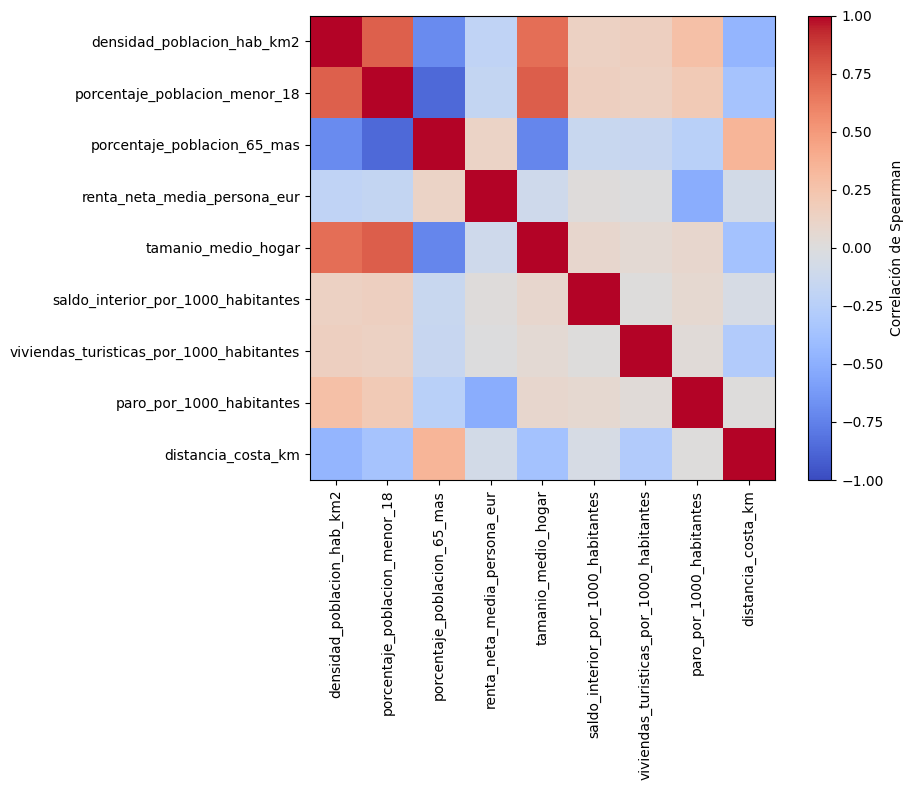

In [11]:
numericas = df.select_dtypes(include=np.number)
asimetria = numericas.skew().sort_values(key=abs, ascending=False).to_frame('asimetria')
display(asimetria.head(30))

variables_revision = [
    'densidad_poblacion_hab_km2',
    'porcentaje_poblacion_menor_18',
    'porcentaje_poblacion_65_mas',
    'renta_neta_media_persona_eur',
    'tamanio_medio_hogar',
    'saldo_interior_por_1000_habitantes',
    'viviendas_turisticas_por_1000_habitantes',
    'paro_por_1000_habitantes',
    'distancia_costa_km',
]
corr = df[variables_revision].corr(method='spearman')
fig, ax = plt.subplots(figsize=(10, 8))
imagen = ax.imshow(corr, vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(len(corr)), corr.columns, rotation=90)
ax.set_yticks(range(len(corr)), corr.index)
fig.colorbar(imagen, ax=ax, label='Correlación de Spearman')
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'correlaciones_iniciales.png', dpi=160, bbox_inches='tight')
plt.show()

## Decisiones pendientes

- Definir si el modelo principal cubrirá toda España o solo municipios con Catastro estatal.
- No imputar automáticamente fuentes con ausencias estructurales.
- Revisar los municipios de población muy reducida antes de tratar los extremos.
- Criminalidad, alquiler y viviendas censales se estudiarán como modelos o análisis secundarios.